# Big Bazaar – Customer Segmentation using Clustering

## 1. Problem Understanding & Objective

**Problem.** Big Bazaar runs the same promotions for almost every shopper, which wastes budget on customers who would buy anyway and misses customers who need a different offer.

**Objective.** Group customers into **3 distinct segments** using only three purchase-related variables, and suggest a promotion strategy for each segment:

| Variable | Meaning |
|---|---|
| `Annual_Income_k` | Annual income (thousands) |
| `Spending_Score` | Spending score, 1-100 |
| `Visit_Frequency` | Store visits per month |

**Scope decisions**
- Only these 3 variables are used. Age, Gender, Basket Value, Recency, Promo Response and Preferred Category are removed from the dataset.
- The number of segments is fixed at **k = 3**. Elbow and silhouette analysis are still shown, to check how k = 3 compares with other choices.

**Steps**
1. Load the raw dataset, keep the 3 features, and clean / pre-process them.
2. Explore the data visually.
3. Build the model (K-Means, compared with Hierarchical and Gaussian Mixture clustering).
4. Evaluate with Silhouette, Davies-Bouldin and Calinski-Harabasz scores, plus a stability test.
5. Profile and name the 3 segments, derive simple segregation rules, and map each segment to a promotion strategy.
6. Save the customers sorted by segment.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.patches import FancyBboxPatch
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3-D projection)
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import cross_val_score, StratifiedKFold
from scipy.cluster.hierarchy import dendrogram, linkage

SEED = 42
K = 3                                                        # number of segments (project requirement)
FEATURES = ["Annual_Income_k", "Spending_Score", "Visit_Frequency"]
PAL = ["#4C72B0", "#DD8452", "#55A868"]                      # one colour per cluster

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
# Folder layout (the notebook lives in notebooks/, so paths go one level up)
DATA_RAW  = "../data/raw"
DATA_PROC = "../data/processed"
RESULTS   = "../results"
DOCS      = "../docs"
for d in (DATA_PROC, RESULTS, DOCS):
    os.makedirs(d, exist_ok=True)

## 2. Project Flow Diagram

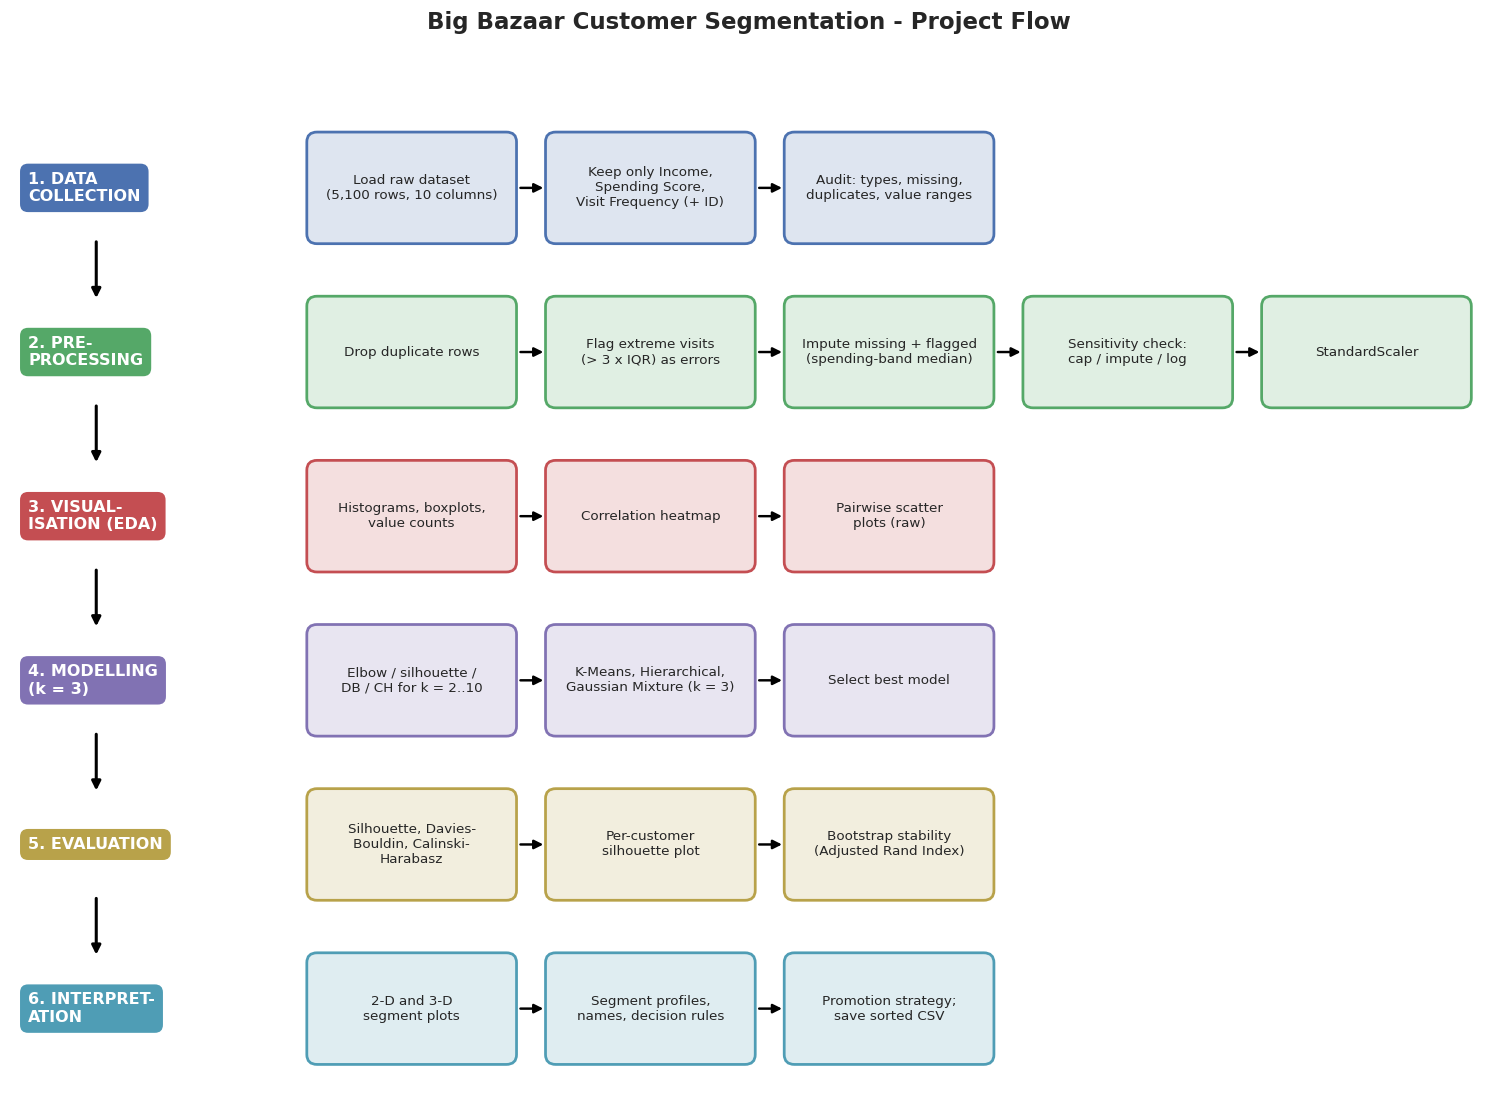

In [2]:
phases = [
    ("1. DATA\nCOLLECTION", "#4C72B0", [
        "Load raw dataset\n(5,100 rows, 10 columns)",
        "Keep only Income,\nSpending Score,\nVisit Frequency (+ ID)",
        "Audit: types, missing,\nduplicates, value ranges"]),
    ("2. PRE-\nPROCESSING", "#55A868", [
        "Drop duplicate rows",
        "Flag extreme visits\n(> 3 x IQR) as errors",
        "Impute missing + flagged\n(spending-band median)",
        "Sensitivity check:\ncap / impute / log",
        "StandardScaler"]),
    ("3. VISUAL-\nISATION (EDA)", "#C44E52", [
        "Histograms, boxplots,\nvalue counts",
        "Correlation heatmap",
        "Pairwise scatter\nplots (raw)"]),
    ("4. MODELLING\n(k = 3)", "#8172B3", [
        "Elbow / silhouette /\nDB / CH for k = 2..10",
        "K-Means, Hierarchical,\nGaussian Mixture (k = 3)",
        "Select best model"]),
    ("5. EVALUATION", "#B8A24A", [
        "Silhouette, Davies-\nBouldin, Calinski-\nHarabasz",
        "Per-customer\nsilhouette plot",
        "Bootstrap stability\n(Adjusted Rand Index)"]),
    ("6. INTERPRET-\nATION", "#4F9DB5", [
        "2-D and 3-D\nsegment plots",
        "Segment profiles,\nnames, decision rules",
        "Promotion strategy;\nsave sorted CSV"]),
]
bw, bh, gap, x0, rh = 2.4, 1.3, 0.4, 3.5, 2.0
fig, ax = plt.subplots(figsize=(17.3, 12.5))
ax.set_xlim(0, 17.3); ax.set_ylim(0, rh * len(phases) + 0.9); ax.axis("off")
ax.set_title("Big Bazaar Customer Segmentation - Project Flow", fontsize=15, fontweight="bold", pad=10)
for r, (title, col, steps) in enumerate(phases):
    y = rh * (len(phases) - 1 - r) + 0.5
    ax.text(0.2, y + bh / 2, title, fontsize=10.5, fontweight="bold", color="white", va="center",
            bbox=dict(boxstyle="round,pad=0.5", fc=col, ec="none"))
    for i, s in enumerate(steps):
        x = x0 + i * (bw + gap)
        ax.add_patch(FancyBboxPatch((x, y), bw, bh, boxstyle="round,pad=0.03,rounding_size=0.12", fc=col, ec="none", alpha=0.18))
        ax.add_patch(FancyBboxPatch((x, y), bw, bh, boxstyle="round,pad=0.03,rounding_size=0.12", fc="none", ec=col, lw=1.8))
        ax.text(x + bw / 2, y + bh / 2, s, ha="center", va="center", fontsize=8.8)
        if i < len(steps) - 1:
            ax.annotate("", xy=(x + bw + gap - 0.02, y + bh / 2), xytext=(x + bw + 0.04, y + bh / 2),
                        arrowprops=dict(arrowstyle="-|>", lw=1.6, color="black"))
    if r < len(phases) - 1:
        ax.annotate("", xy=(1.0, y - rh + bh / 2 + 0.62), xytext=(1.0, y + bh / 2 - 0.62),
                    arrowprops=dict(arrowstyle="-|>", lw=2, color="black"))
fig.savefig(f"{DOCS}/flow_diagram.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Data Collection

The raw file has 5,000 customers (plus duplicate rows) and was generated for this project:
- **Annual Income and Spending Score** (and Age / Gender, not used here) are resampled from the public *Mall Customers* dataset (Kaggle, 200 real customers) with small random noise added, to scale it up to 5,000 customers.
- **Visit_Frequency** (and the other behavioural columns, not used here) is simulated from the columns above with a fixed random seed.
- Realistic data problems (missing values, outliers, duplicate rows) were added so that the cleaning step is meaningful.

For this project only three variables are kept. The other columns are dropped in the next cell.

| Kept column | Description |
|---|---|
| CustomerID | Unique id (identifier only, not used for modelling) |
| Annual_Income_k | Annual income (thousands) |
| Spending_Score | Spending score, 1-100 |
| Visit_Frequency | Store visits per month |

**Removed columns:** Gender, Age, Avg_Basket_Value, Recency_Days, Promo_Response_Pct, Preferred_Category.

In [3]:
raw_full = pd.read_csv(f"{DATA_RAW}/bigbazaar_hybrid_raw_5k.csv")
print("Full raw file:", raw_full.shape)

KEEP = ["CustomerID"] + FEATURES
print("Removed columns:", [c for c in raw_full.columns if c not in KEEP])
raw = raw_full[KEEP].copy()
raw.to_csv(f"{DATA_PROC}/bigbazaar_raw_3features.csv", index=False)
print("Kept columns   :", list(raw.columns), "->", raw.shape)
display(raw.head())

Full raw file: (5100, 10)
Removed columns: ['Gender', 'Age', 'Avg_Basket_Value', 'Recency_Days', 'Promo_Response_Pct', 'Preferred_Category']
Kept columns   : ['CustomerID', 'Annual_Income_k', 'Spending_Score', 'Visit_Frequency'] -> (5100, 4)


,CustomerID,Annual_Income_k,Spending_Score,Visit_Frequency
0,1,15,6,3.0
1,2,15,73,6.0
2,3,15,41,3.0
3,4,15,99,10.0
4,5,15,9,2.0


In [4]:
audit = pd.DataFrame({"dtype": raw.dtypes.astype(str),
                      "missing": raw.isna().sum(),
                      "missing_%": (raw.isna().mean() * 100).round(2),
                      "min": raw.min(numeric_only=True), "max": raw.max(numeric_only=True)})
display(audit)
print("Duplicate rows          :", raw.duplicated().sum())
print("Duplicate CustomerIDs   :", raw["CustomerID"].duplicated().sum())
print("Spending_Score outside 1-100 :", (~raw["Spending_Score"].between(1, 100)).sum())
print("Annual_Income_k <= 0         :", (raw["Annual_Income_k"] <= 0).sum())
print("Visit_Frequency < 1          :", (raw["Visit_Frequency"] < 1).sum())
display(raw[FEATURES].describe().T.round(2))

,dtype,missing,missing_%,min,max
CustomerID,int64,0,0.00,1.0,5000.0
Annual_Income_k,int64,0,0.00,15.0,137.0
Spending_Score,int64,0,0.00,1.0,99.0
Visit_Frequency,float64,206,4.04,1.0,39.0


Duplicate rows          : 100
Duplicate CustomerIDs   : 100
Spending_Score outside 1-100 : 0
Annual_Income_k <= 0         : 0
Visit_Frequency < 1          : 0


,count,mean,std,min,25%,50%,75%,max
Annual_Income_k,5100.0,60.50,26.05,15.0,41.0,61.0,78.0,137.0
Spending_Score,5100.0,50.35,25.85,1.0,33.0,50.0,71.0,99.0
Visit_Frequency,4894.0,5.73,4.39,1.0,3.0,5.0,7.0,39.0


## 4. Exploratory Data Analysis (raw data)

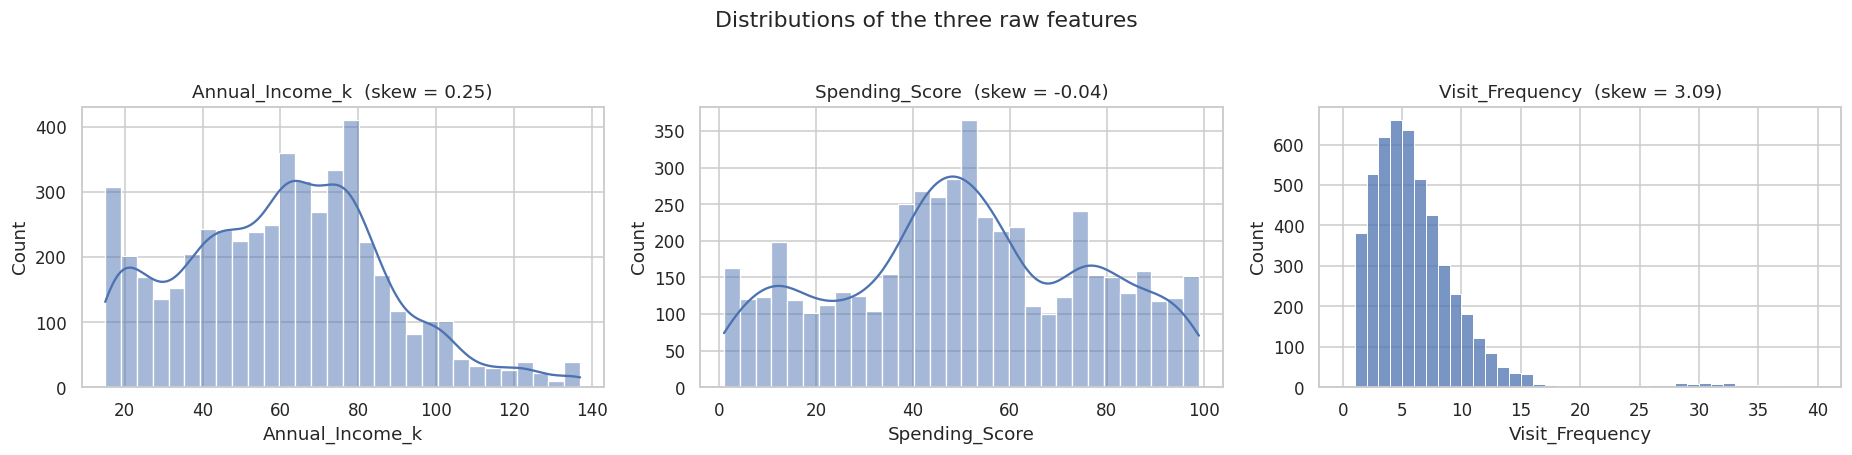

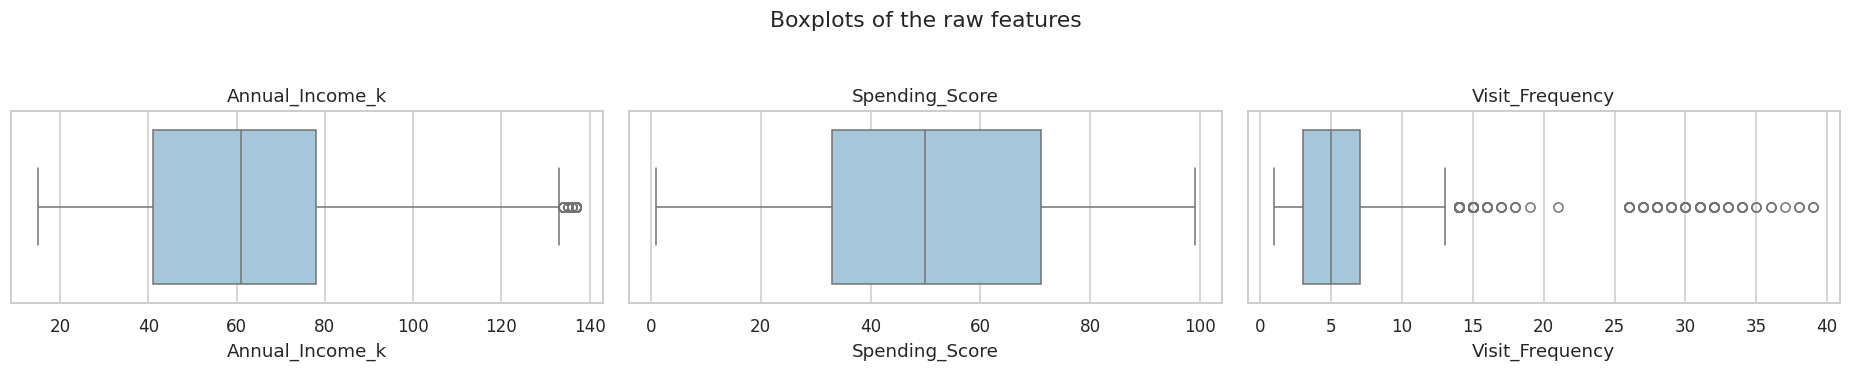

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, c in zip(axes, FEATURES):
    sns.histplot(raw[c].dropna(), bins=range(0, 41) if c == "Visit_Frequency" else 30, kde=(c != "Visit_Frequency"), ax=ax, color="#4C72B0")
    ax.set_title(f"{c}  (skew = {raw[c].skew():.2f})")
plt.suptitle("Distributions of the three raw features", y=1.03); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 3.2))
for ax, c in zip(axes, FEATURES):
    sns.boxplot(x=raw[c], ax=ax, color="#9ecae1"); ax.set_title(c)
plt.suptitle("Boxplots of the raw features", y=1.05); plt.tight_layout(); plt.show()

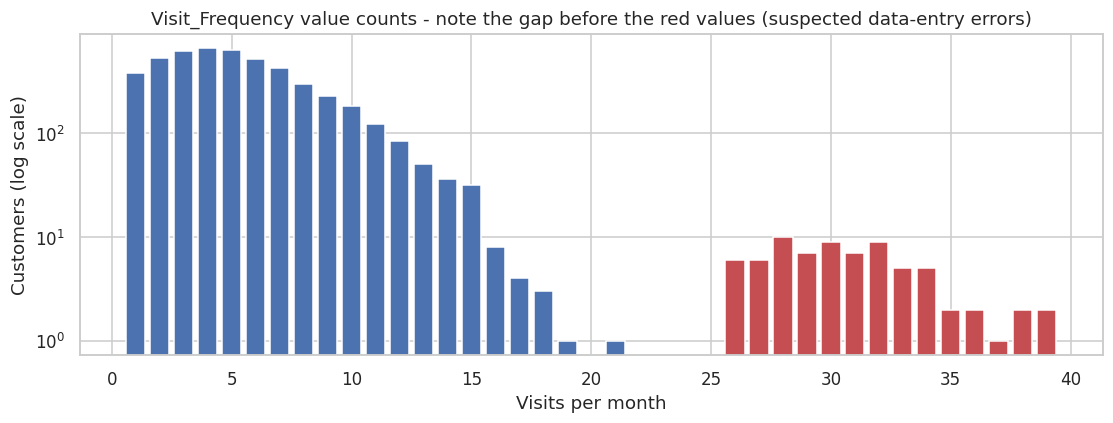

Largest values: {26.0: 6, 27.0: 6, 28.0: 10, 29.0: 7, 30.0: 9, 31.0: 7, 32.0: 9, 33.0: 5, 34.0: 5, 35.0: 2, 36.0: 2, 37.0: 1, 38.0: 2, 39.0: 2}


In [6]:
# Visit_Frequency value counts on a log scale: is there a gap between genuine and suspicious values?
vc = raw["Visit_Frequency"].value_counts().sort_index()
plt.figure(figsize=(12, 3.8))
plt.bar(vc.index, vc.values, color=["#4C72B0" if v <= 21 else "#C44E52" for v in vc.index])
plt.yscale("log"); plt.xlabel("Visits per month"); plt.ylabel("Customers (log scale)")
plt.title("Visit_Frequency value counts - note the gap before the red values (suspected data-entry errors)")
plt.show()
print("Largest values:", vc.tail(14).to_dict())

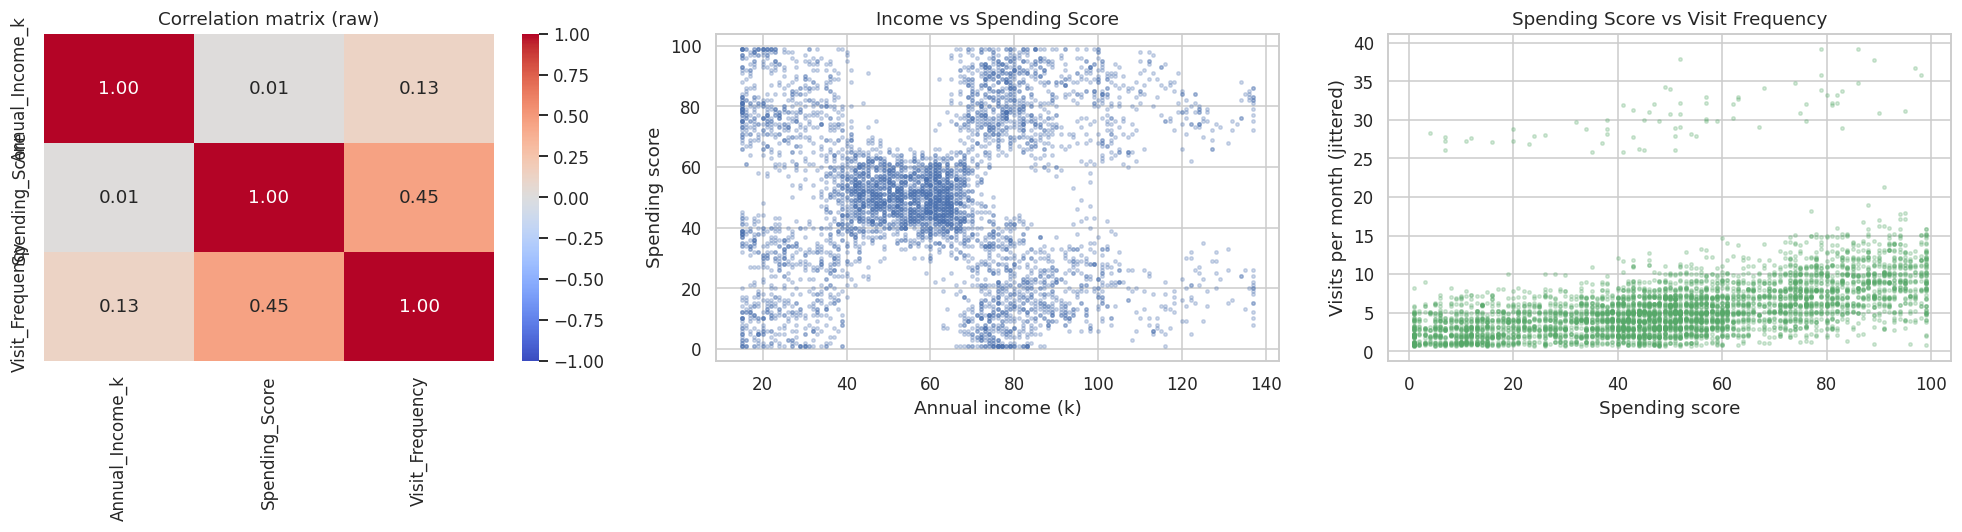

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(raw[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlation matrix (raw)")
axes[1].scatter(raw["Annual_Income_k"], raw["Spending_Score"], s=5, alpha=0.25, color="#4C72B0")
axes[1].set_xlabel("Annual income (k)"); axes[1].set_ylabel("Spending score"); axes[1].set_title("Income vs Spending Score")
axes[2].scatter(raw["Spending_Score"], raw["Visit_Frequency"] + np.random.default_rng(SEED).uniform(-0.3, 0.3, len(raw)), s=5, alpha=0.25, color="#55A868")
axes[2].set_xlabel("Spending score"); axes[2].set_ylabel("Visits per month (jittered)"); axes[2].set_title("Spending Score vs Visit Frequency")
plt.tight_layout(); plt.show()

**Observations**
- `Visit_Frequency` has **206 missing values** (about 4%; 200 remain once the duplicates are removed), **100 duplicate rows**, and a handful of very large values. Genuine values end around 21 visits; a separate group starts at 26 or more, with an empty gap in between. Those are almost certainly data-entry errors.
- `Annual_Income_k` and `Spending_Score` are almost uncorrelated, while `Spending_Score` and `Visit_Frequency` are moderately positively correlated: customers who score high on spending also visit more often.
- The income vs spending scatter plot shows **about five dense blocks** rather than three. With k = 3 some of these blocks will necessarily be merged; Section 6 quantifies the cost of that.
- Income has a few high values (up to 137). These are genuine high earners that also exist in the original Mall Customers data, so they are kept.

## 5. Data Cleaning & Pre-processing

| Step | Method | Reason |
|---|---|---|
| 1 | Drop duplicate rows | Duplicates would count some customers twice |
| 2 | Treat `Visit_Frequency` values above the **3 x IQR fence** as data-entry errors (set to missing) | Genuine values end around 21 and the suspicious group starts at 26 with an empty gap between them, so these look like errors, not real behaviour. Capping them instead would leave 72 artificial "heavy visitors" |
| 3 | Impute all missing `Visit_Frequency` (original gaps + step 2) with the **median of the customer's spending-score band** | Visits rise with spending score, so a band median is more accurate than one global median (tested below) |
| 4 | Keep income and spending score unchanged | Both are complete, in valid range, and the high incomes are genuine |
| 5 | Sensitivity check: capping vs imputing, and a log transform | Confirms the pre-processing choices do not drive the result |
| 6 | StandardScaler | Clustering uses distances, so features need a common scale |

In [8]:
# Step 1 - duplicates
n0 = len(raw)
df = raw.drop_duplicates().reset_index(drop=True)
print(f"Step 1: removed {n0 - len(df)} duplicate rows -> {len(df)} customers "
      f"(CustomerID unique: {df['CustomerID'].is_unique}). Missing Visit_Frequency now: {df['Visit_Frequency'].isna().sum()}")
df_dedup = df.copy()                                   # kept for the sensitivity check

Step 1: removed 100 duplicate rows -> 5000 customers (CustomerID unique: True). Missing Visit_Frequency now: 200


In [9]:
# Step 2 - outliers.  IQR fences for the three features (1.5 x IQR is the usual rule, 3 x IQR flags only extreme values)
rows = []
for c in FEATURES:
    a1, a3 = df[c].quantile([.25, .75]); w = a3 - a1
    rows.append([c, int((df[c] > a3 + 1.5 * w).sum() + (df[c] < a1 - 1.5 * w).sum()),
                 int((df[c] > a3 + 3 * w).sum() + (df[c] < a1 - 3 * w).sum()), a3 + 1.5 * w, a3 + 3 * w])
display(pd.DataFrame(rows, columns=["Feature", "Outliers (1.5 x IQR)", "Outliers (3 x IQR)", "Upper fence 1.5x", "Upper fence 3x"]).round(1))

q1, q3 = df["Visit_Frequency"].quantile([.25, .75]); iqr = q3 - q1
FENCE = q3 + 3 * iqr
vf_before = df["Visit_Frequency"].copy()
is_error = df["Visit_Frequency"] > FENCE
df.loc[is_error, "Visit_Frequency"] = np.nan
print(f"\nStep 2: {is_error.sum()} Visit_Frequency values above {FENCE:.0f} treated as data-entry errors (set to missing). "
      f"A 1.5 x IQR rule would have flagged {(vf_before > q3 + 1.5 * iqr).sum()}, including genuine heavy visitors.")
print("Income / Spending Score left unchanged (the high incomes are genuine).")

,Feature,Outliers (1.5 x IQR),Outliers (3 x IQR),Upper fence 1.5x,Upper fence 3x
0,Annual_Income_k,38,0,132.0,186.0
1,Spending_Score,0,0,128.0,185.0
2,Visit_Frequency,153,72,13.0,19.0



Step 2: 72 Visit_Frequency values above 19 treated as data-entry errors (set to missing). A 1.5 x IQR rule would have flagged 153, including genuine heavy visitors.
Income / Spending Score left unchanged (the high incomes are genuine).


In [10]:
# Step 3 - imputation.  First test which method is more accurate:
# hide 10% of the KNOWN visit counts, impute them both ways, and compare the error.
bins, labels = [0, 20, 40, 60, 80, 100], ["1-20", "21-40", "41-60", "61-80", "81-100"]
known = df.dropna(subset=["Visit_Frequency"]).copy()
known["band"] = pd.cut(known["Spending_Score"], bins=bins, labels=labels)
hide = np.random.default_rng(SEED).random(len(known)) < 0.10
truth = known.loc[hide, "Visit_Frequency"]
global_med = known.loc[~hide, "Visit_Frequency"].median()
band_med = known.loc[~hide].groupby("band", observed=True)["Visit_Frequency"].median()
pred_band = known.loc[hide, "band"].map(band_med).astype(float)
mae_global = (truth - global_med).abs().mean(); mae_band = (truth - pred_band).abs().mean()
print(f"Mean absolute error on hidden values -> global median: {mae_global:.2f} | spending-band median: {mae_band:.2f}")
display(band_med.rename("median visits").to_frame().T)

Mean absolute error on hidden values -> global median: 2.40 | spending-band median: 1.93


band,1-20,21-40,41-60,61-80,81-100
median visits,3.0,4.0,5.0,7.0,9.0


Step 3: imputed 272 values (200 originally missing + 72 errors). Missing values left: 0


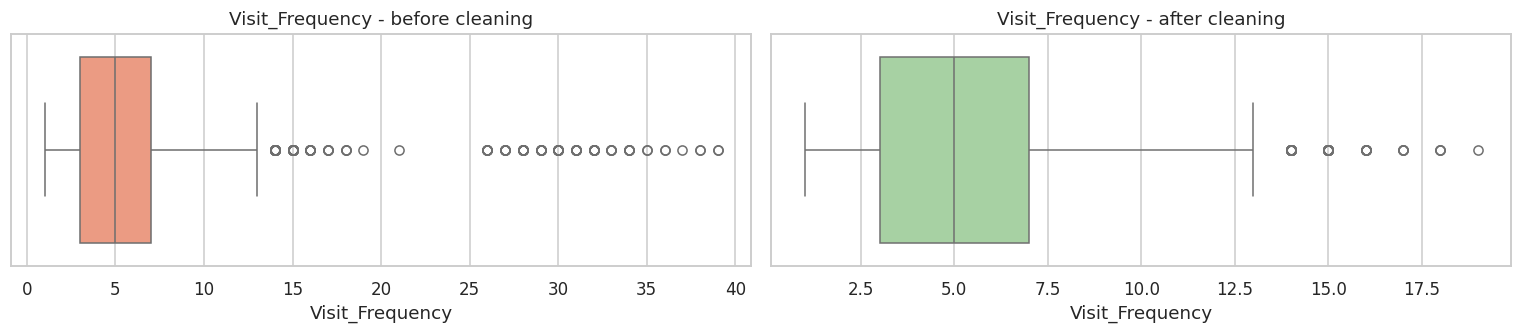

Skew of Visit_Frequency after cleaning: 0.85


In [11]:
# Apply the better method (spending-band median) to every missing value (original gaps + errors from step 2)
band = pd.cut(df["Spending_Score"], bins=bins, labels=labels)
n_missing = df["Visit_Frequency"].isna().sum()
df["Visit_Frequency"] = df["Visit_Frequency"].fillna(df.groupby(band, observed=True)["Visit_Frequency"].transform("median")).round()
print(f"Step 3: imputed {n_missing} values ({n_missing - is_error.sum()} originally missing + {is_error.sum()} errors). "
      f"Missing values left: {df.isna().sum().sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.2))
sns.boxplot(x=vf_before, ax=axes[0], color="#fc9272"); axes[0].set_title("Visit_Frequency - before cleaning")
sns.boxplot(x=df["Visit_Frequency"], ax=axes[1], color="#a1d99b"); axes[1].set_title("Visit_Frequency - after cleaning")
plt.tight_layout(); plt.show()
print(f"Skew of Visit_Frequency after cleaning: {df['Visit_Frequency'].skew():.2f}")

In [12]:
# Step 5 - sensitivity check: does the way extreme visits are treated, or a log transform, change the clusters?
band_all = pd.cut(df_dedup["Spending_Score"], bins=bins, labels=labels)
def fit_variant(policy, use_log=False):
    v = df_dedup["Visit_Frequency"].copy()
    if policy == "cap 1.5":    v = v.clip(upper=q3 + 1.5 * iqr)
    elif policy == "cap 3":    v = v.clip(upper=FENCE)
    elif policy == "impute 3": v = v.where(~(v > FENCE))
    v = v.fillna(v.groupby(band_all, observed=True).transform("median")).round()
    if use_log: v = np.log1p(v)
    Xv = StandardScaler().fit_transform(pd.concat([df_dedup[["Annual_Income_k", "Spending_Score"]], v], axis=1))
    lab = KMeans(K, n_init=20, random_state=SEED).fit_predict(Xv)
    return silhouette_score(Xv, lab), lab

variants = {"Leave extreme values as they are": ("none", False), "Cap at 1.5 x IQR": ("cap 1.5", False),
            "Cap at 3 x IQR": ("cap 3", False), "Impute above 3 x IQR (chosen)": ("impute 3", False),
            "Impute above 3 x IQR + log1p": ("impute 3", True)}
res = {n: fit_variant(*a) for n, a in variants.items()}
ref = res["Impute above 3 x IQR (chosen)"][1]
sens = pd.DataFrame({"Silhouette (k=3)": {n: r[0] for n, r in res.items()},
                     "ARI vs chosen": {n: adjusted_rand_score(ref, r[1]) for n, r in res.items()}}).round(3)
display(sens)

,Silhouette (k=3),ARI vs chosen
Leave extreme values as they are,0.358,0.808
Cap at 1.5 x IQR,0.339,0.968
Cap at 3 x IQR,0.343,0.916
Impute above 3 x IQR (chosen),0.341,1.000
Impute above 3 x IQR + log1p,0.311,0.408


**Reading the sensitivity table.**
- Leaving the 72 extreme values untouched changes the segments noticeably (ARI about 0.81 against the chosen version), so treating them is worthwhile.
- Whether the extreme values are capped (at 1.5 x or 3 x IQR) or imputed barely matters (ARI 0.92 to 0.97), so the result does not hinge on that choice. Imputing was chosen because capping leaves the errors looking like very heavy visitors.
- A log transform lowers the silhouette and reshuffles many customers (ARI about 0.41), so `Visit_Frequency` stays on its original scale. It is also easier to explain "visits per month" than "log visits".
- Silhouette values are not strictly comparable between variants because each variant scales the data differently; the ARI column is the more reliable comparison.

In [13]:
# Step 6 - scaling
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])
print("Scaled matrix:", X.shape, "| column means ~", X.mean(axis=0).round(3), "| column std ~", X.std(axis=0).round(3))

summary_clean = pd.DataFrame({"Rows": [len(raw), len(df)],
                              "Missing values": [raw[FEATURES].isna().sum().sum(), df[FEATURES].isna().sum().sum()],
                              "Duplicate rows": [raw.duplicated().sum(), df.duplicated().sum()],
                              "Max Visit_Frequency": [raw["Visit_Frequency"].max(), df["Visit_Frequency"].max()]},
                             index=["Raw", "Cleaned"])
display(summary_clean)
display(df[FEATURES].describe().T.round(2))

Scaled matrix: (5000, 3) | column means ~ [ 0.  0. -0.] | column std ~ [1. 1. 1.]


,Rows,Missing values,Duplicate rows,Max Visit_Frequency
Raw,5100,206,100,39.0
Cleaned,5000,0,0,19.0


,count,mean,std,min,25%,50%,75%,max
Annual_Income_k,5000.0,60.57,26.01,15.0,42.0,61.0,78.0,137.0
Spending_Score,5000.0,50.39,25.86,1.0,33.0,50.0,71.0,99.0
Visit_Frequency,5000.0,5.35,3.06,1.0,3.0,5.0,7.0,19.0


## 6. Model Development

### 6.1 Checking the number of clusters

The number of segments is **fixed at k = 3** by the project requirement. K-Means is still run for k = 2 to 10 to see how k = 3 compares:
- **Elbow (inertia / WCSS):** where adding clusters stops helping much.
- **Silhouette** (higher is better), **Davies-Bouldin** (lower is better), **Calinski-Harabasz** (higher is better).

,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,,
2,9413.782,0.353,1.157,2965.861
3,6982.391,0.341,0.990,2868.937
4,5594.965,0.343,1.029,2799.398
5,4442.537,0.370,0.921,2967.591
6,3869.060,0.340,0.962,2873.467
7,3330.428,0.341,0.983,2915.850
8,3075.210,0.339,0.976,2765.365
9,2841.931,0.328,1.059,2669.000
10,2632.352,0.313,1.086,2604.967


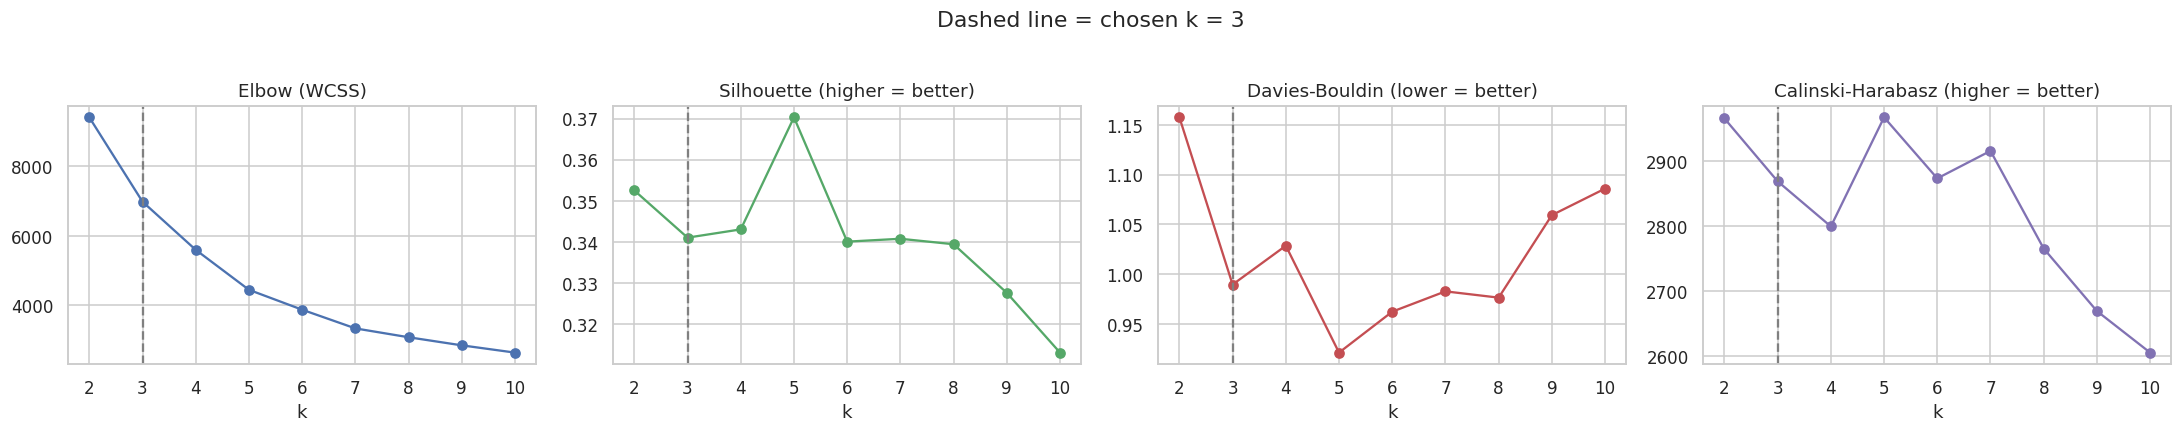

k = 3 -> silhouette 0.341; best silhouette is at k = 5 (0.370).


In [14]:
def evaluate(Xm, lab):
    return {"Silhouette": silhouette_score(Xm, lab), "Davies-Bouldin": davies_bouldin_score(Xm, lab),
            "Calinski-Harabasz": calinski_harabasz_score(Xm, lab)}

rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    rows.append({"k": k, "Inertia": km.inertia_, **evaluate(X, km.labels_)})
k_table = pd.DataFrame(rows).set_index("k")
display(k_table.round(3))

fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
for ax, (col, title, c) in zip(axes, [("Inertia", "Elbow (WCSS)", "#4C72B0"), ("Silhouette", "Silhouette (higher = better)", "#55A868"),
                                      ("Davies-Bouldin", "Davies-Bouldin (lower = better)", "#C44E52"),
                                      ("Calinski-Harabasz", "Calinski-Harabasz (higher = better)", "#8172B3")]):
    ax.plot(k_table.index, k_table[col], "o-", color=c); ax.axvline(K, ls="--", color="grey"); ax.set_title(title); ax.set_xlabel("k")
plt.suptitle("Dashed line = chosen k = 3", y=1.03); plt.tight_layout(); plt.show()

best_sil_k = int(k_table["Silhouette"].idxmax())
print(f"k = 3 -> silhouette {k_table.loc[K, 'Silhouette']:.3f}; best silhouette is at k = {best_sil_k} ({k_table.loc[best_sil_k, 'Silhouette']:.3f}).")

,ARI_mean,ARI_std
2,0.974,0.014
3,0.988,0.009
4,0.865,0.159
5,0.985,0.011
6,0.880,0.126
7,0.918,0.106
8,0.878,0.094


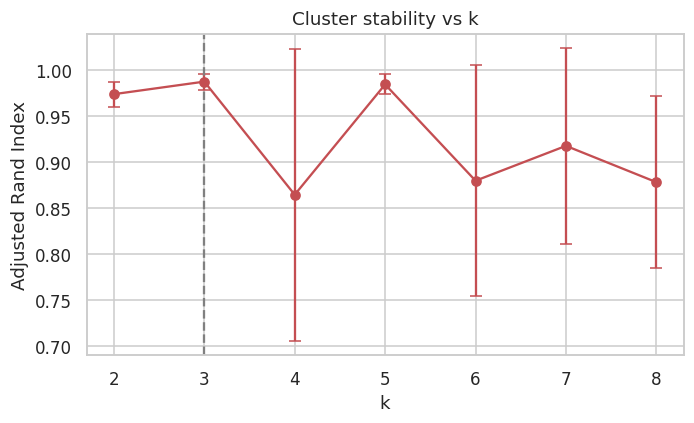

In [15]:
# How reproducible are the clusters for each k?  (80% bootstrap subsamples, 30 repeats)
rng_b = np.random.default_rng(SEED)
def stability(k, B=30, frac=0.8):
    base = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    aris = []
    for b in range(B):
        idx = rng_b.choice(len(X), int(frac * len(X)), replace=False)
        km = KMeans(n_clusters=k, n_init=5, random_state=b).fit(X[idx])
        aris.append(adjusted_rand_score(base.labels_, km.predict(X)))
    return np.mean(aris), np.std(aris)

stab = pd.DataFrame({k: stability(k) for k in range(2, 9)}, index=["ARI_mean", "ARI_std"]).T
display(stab.round(3))
plt.figure(figsize=(7, 3.8))
plt.errorbar(stab.index, stab["ARI_mean"], yerr=stab["ARI_std"], fmt="o-", capsize=4, color="#C44E52")
plt.axvline(K, ls="--", color="grey"); plt.xlabel("k"); plt.ylabel("Adjusted Rand Index"); plt.title("Cluster stability vs k"); plt.show()

**Reading the k analysis.**
- The metrics sit in a narrow band. Silhouette is 0.341 at k = 3 and peaks at 0.370 at k = 5; Davies-Bouldin is 0.990 at k = 3 against its best of 0.921 at k = 5; Calinski-Harabasz is 2,869 at k = 3 against about 2,970 at k = 2 and k = 5.
- k = 5 is marginally the best statistically, which matches the five dense blocks seen in the income vs spending scatter plot.
- k = 3 is nevertheless a sound choice: it is highly reproducible (bootstrap ARI about 0.99), whereas k = 4 and k = 6 are clearly less stable (about 0.87 to 0.88).
- The price of k = 3 is that natural blocks are merged into broader segments. This is discussed in the interpretation and limitations.

### 6.2 K-Means vs Hierarchical vs Gaussian Mixture (k = 3)

All three models are trained with k = 3 on the same scaled data and compared on three metrics:
- **Silhouette** (-1 to 1, higher is better): how close each customer is to its own cluster vs the nearest other cluster.
- **Davies-Bouldin** (lower is better): average similarity between each cluster and its most similar one.
- **Calinski-Harabasz** (higher is better): ratio of between-cluster to within-cluster spread.

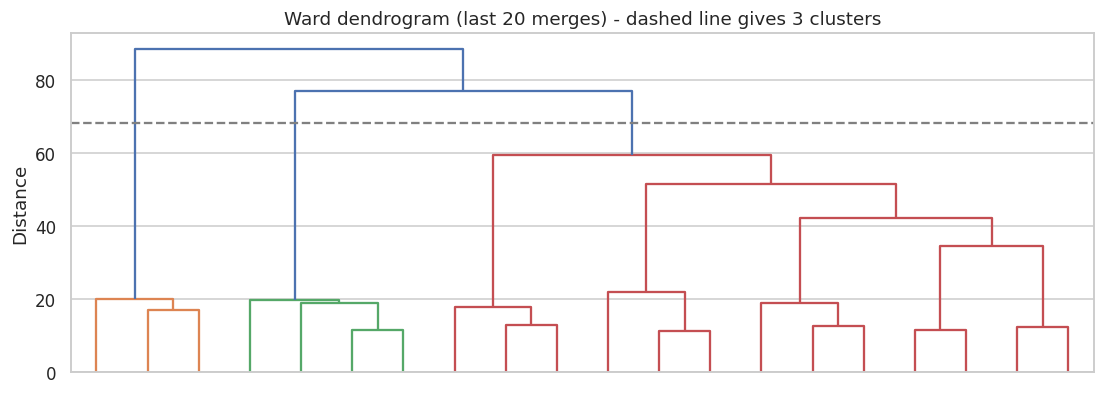

In [16]:
Z = linkage(X, method="ward")
cut = (Z[-K, 2] + Z[-(K - 1), 2]) / 2
plt.figure(figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=20, color_threshold=cut, no_labels=True)
plt.axhline(cut, ls="--", color="grey"); plt.title("Ward dendrogram (last 20 merges) - dashed line gives 3 clusters"); plt.ylabel("Distance"); plt.show()

In [17]:
models = {
    "K-Means":             KMeans(n_clusters=K, n_init=20, random_state=SEED).fit_predict(X),
    "Hierarchical (Ward)": AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X),
    "Gaussian Mixture":    GaussianMixture(n_components=K, covariance_type="full", n_init=5, random_state=SEED).fit(X).predict(X),
}
results = pd.DataFrame({n: evaluate(X, lab) for n, lab in models.items()}).T.round(3)
display(results)

agree = pd.DataFrame([[adjusted_rand_score(a, b) for b in models.values()] for a in models.values()],
                     index=models.keys(), columns=models.keys()).round(2)
print("Agreement between models (Adjusted Rand Index, 1 = identical):"); display(agree)

best_model = results["Silhouette"].idxmax()
print("Selected model:", best_model)

,Silhouette,Davies-Bouldin,Calinski-Harabasz
K-Means,0.341,0.990,2868.937
Hierarchical (Ward),0.291,0.962,2112.302
Gaussian Mixture,0.294,1.210,2065.410


Agreement between models (Adjusted Rand Index, 1 = identical):


,K-Means,Hierarchical (Ward),Gaussian Mixture
K-Means,1.00,0.59,0.55
Hierarchical (Ward),0.59,1.00,0.56
Gaussian Mixture,0.55,0.56,1.00


Selected model: K-Means


In [18]:
# Give clusters a fixed, meaningful order: Cluster 0 = lowest average spending score ... Cluster 2 = highest
def reorder(lab):
    order = pd.Series(df["Spending_Score"].values).groupby(lab).mean().sort_values().index
    return pd.Series(lab).map({old: new for new, old in enumerate(order)}).values

df["Cluster"] = reorder(models[best_model])
print(df["Cluster"].value_counts().sort_index().rename("customers").to_frame().T)

Cluster      0     1     2
customers  970  2708  1322


**Reading the comparison.**
- K-Means has the best Silhouette (0.341) and Calinski-Harabasz (2,869) scores and is selected. Hierarchical (Ward) has a marginally better Davies-Bouldin score (0.962 vs 0.990) but is clearly lower on the other two; the Gaussian Mixture is weakest on all three.
- The models agree only moderately with each other (ARI 0.55 to 0.59). Customers form a continuous spread rather than isolated islands, so the boundaries between segments are soft, whichever algorithm is used.

## 7. Performance Evaluation

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Bootstrap stability (ARI)
K-Means,0.341,0.99,2868.937,0.988


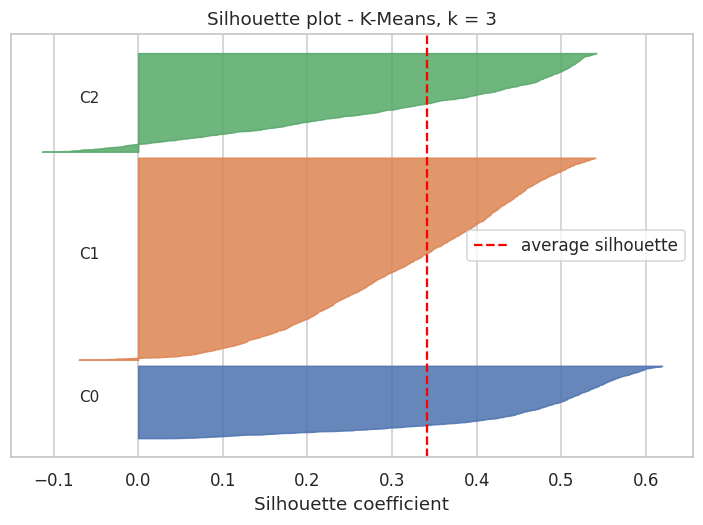

Average silhouette per cluster:


,0,1,2
avg silhouette,0.453,0.317,0.308


Customers with a negative silhouette (possibly on the boundary): 2.6%


In [19]:
final = results.loc[[best_model]].copy()
final["Bootstrap stability (ARI)"] = round(stab.loc[K, "ARI_mean"], 3)
display(final)

sil = silhouette_samples(X, df["Cluster"])
fig, ax = plt.subplots(figsize=(8, 5))
y_low = 10
for c in range(K):
    s = np.sort(sil[df["Cluster"] == c]); y_up = y_low + len(s)
    ax.fill_betweenx(np.arange(y_low, y_up), 0, s, color=PAL[c], alpha=0.85)
    ax.text(-0.07, y_low + 0.5 * len(s), f"C{c}", fontsize=10); y_low = y_up + 80
ax.axvline(silhouette_score(X, df["Cluster"]), color="red", ls="--", label="average silhouette")
ax.set_xlabel("Silhouette coefficient"); ax.set_yticks([]); ax.legend(); ax.set_title(f"Silhouette plot - {best_model}, k = 3"); plt.show()

per_cluster = pd.Series(sil).groupby(df["Cluster"].values).mean().round(3).rename("avg silhouette")
print("Average silhouette per cluster:"); display(per_cluster.to_frame().T)
print(f"Customers with a negative silhouette (possibly on the boundary): {(sil < 0).mean():.1%}")

**Reading the evaluation.**
- An average silhouette of 0.34 indicates a reasonable but not sharp structure, which is typical for customer data where behaviour is continuous.
- Cluster 0 is the most compact (silhouette 0.45). Clusters 1 and 2 are looser (about 0.31), and only 2.6% of customers sit on a boundary with a negative silhouette.
- The bootstrap stability of 0.988 means the same three segments are recovered when 20% of customers are removed at random. This is likely to be slightly optimistic because the 5,000 rows were generated from 200 original customers (see Limitations).

## 8. Visualisation of the Segments

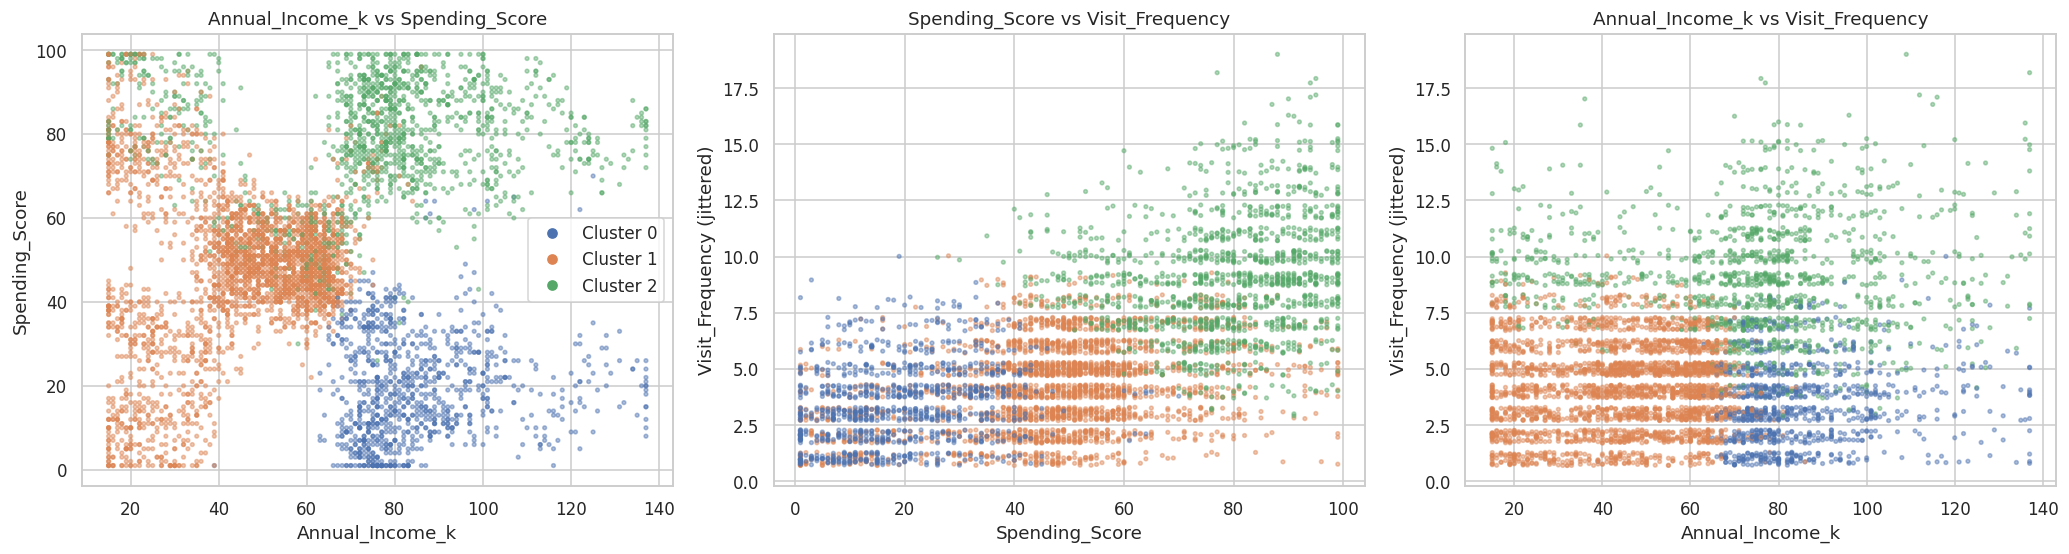

In [20]:
colors = df["Cluster"].map(dict(enumerate(PAL)))
jit = np.random.default_rng(SEED).uniform(-0.3, 0.3, len(df))
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
pairs = [("Annual_Income_k", "Spending_Score"), ("Spending_Score", "Visit_Frequency"), ("Annual_Income_k", "Visit_Frequency")]
for ax, (a, b) in zip(axes, pairs):
    yv = df[b] + (jit if b == "Visit_Frequency" else 0)
    ax.scatter(df[a], yv, c=colors, s=6, alpha=0.45)
    ax.set_xlabel(a); ax.set_ylabel(b + (" (jittered)" if b == "Visit_Frequency" else "")); ax.set_title(f"{a} vs {b}")
handles = [plt.Line2D([], [], marker="o", ls="", color=PAL[c], label=f"Cluster {c}") for c in range(K)]
axes[0].legend(handles=handles); plt.tight_layout(); plt.show()

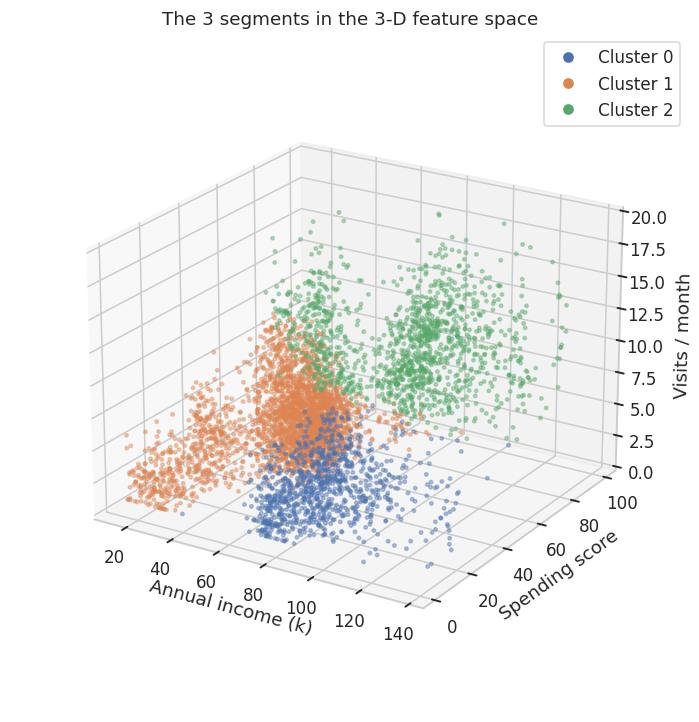

In [21]:
fig = plt.figure(figsize=(10, 8)); ax = fig.add_subplot(111, projection="3d")
ax.scatter(df["Annual_Income_k"], df["Spending_Score"], df["Visit_Frequency"], c=colors, s=5, alpha=0.4)
ax.set_xlabel("Annual income (k)"); ax.set_ylabel("Spending score"); ax.set_zlabel("Visits / month", labelpad=8)
ax.set_box_aspect(None, zoom=0.88)
ax.set_title("The 3 segments in the 3-D feature space"); ax.view_init(elev=22, azim=-58); ax.legend(handles=handles); plt.show()

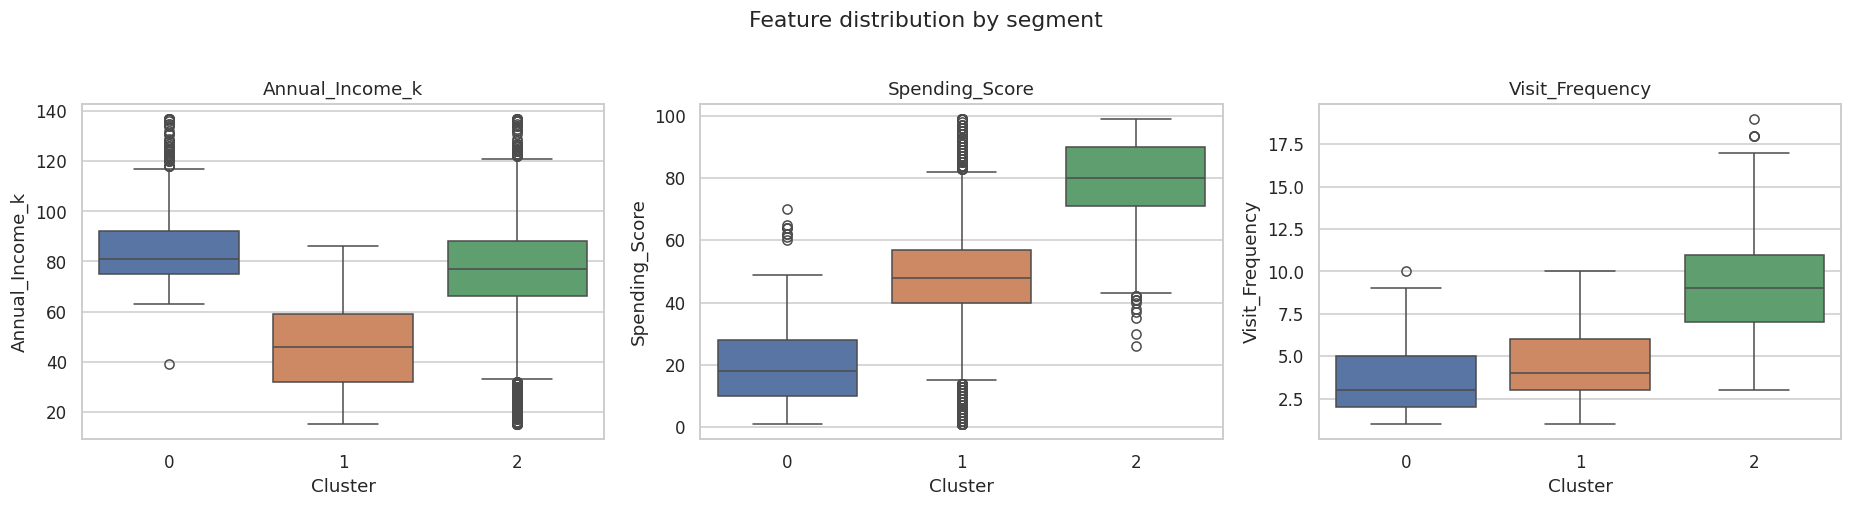

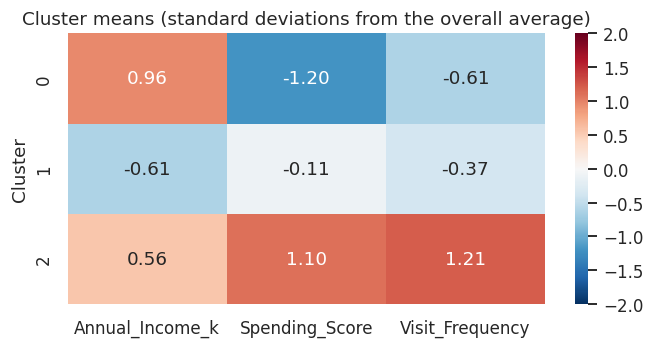

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, c in zip(axes, FEATURES):
    sns.boxplot(data=df, x="Cluster", y=c, hue="Cluster", palette=PAL, legend=False, ax=ax); ax.set_title(c)
plt.suptitle("Feature distribution by segment", y=1.02); plt.tight_layout(); plt.show()

z_means = (df.groupby("Cluster")[FEATURES].mean() - df[FEATURES].mean()) / df[FEATURES].std()
plt.figure(figsize=(7, 3.2))
sns.heatmap(z_means, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-2, vmax=2)
plt.title("Cluster means (standard deviations from the overall average)"); plt.show()

## 9. Interpretation: Segment Profiles, Names, Rules & Promotion Strategy

In [23]:
profile = df.groupby("Cluster").agg(Customers=("CustomerID", "count"), Income_k=("Annual_Income_k", "mean"),
                                    Spending_Score=("Spending_Score", "mean"), Visits_per_month=("Visit_Frequency", "mean"))
profile.insert(1, "Share_%", profile["Customers"] / len(df) * 100)
display(profile.round(1))

typical = pd.DataFrame({f"{f}: typical range (P10-P90)": df.groupby("Cluster")[f].apply(lambda s: f"{s.quantile(.1):.0f} - {s.quantile(.9):.0f}")
                        for f in FEATURES})
display(typical)

,Customers,Share_%,Income_k,Spending_Score,Visits_per_month
Cluster,,,,,
0,970,19.4,85.5,19.4,3.5
1,2708,54.2,44.6,47.6,4.2
2,1322,26.4,75.0,78.7,9.1


,Annual_Income_k: typical range (P10-P90),Spending_Score: typical range (P10-P90),Visit_Frequency: typical range (P10-P90)
Cluster,,,
0,71 - 105,4 - 36,1 - 6
1,20 - 64,21 - 72,2 - 7
2,34 - 104,59 - 95,6 - 12


Each segment is named from its standardised averages in the heatmap above (high = more than +0.5 SD, low = less than -0.5 SD compared with all customers).

In [24]:
def name_segment(r):
    if r["Spending_Score"] > 0.5 and r["Visit_Frequency"] > 0.5: return "High-Value Frequent Shoppers"
    if r["Annual_Income_k"] > 0.5 and r["Spending_Score"] < -0.5: return "Cautious Affluent"
    if r["Annual_Income_k"] < -0.5 and r["Spending_Score"] < -0.5: return "Budget Conservatives"
    return "Everyday Mainstream"

strategy = {
    "High-Value Frequent Shoppers": "VIP loyalty tier, early access to new launches, bundles and cross-sell. Avoid heavy discounts - they already buy.",
    "Cautious Affluent": "Personalised, quality-led offers and exclusive deals to raise visit frequency and unlock unspent budget.",
    "Budget Conservatives": "Everyday low prices on staples, bulk packs, cashback and low-cost SMS offers.",
    "Everyday Mainstream": "Loyalty points, weekly deals and category cross-sell to nudge visits and basket size upward.",
}
names = z_means.apply(name_segment, axis=1)
assert names.is_unique, "Two clusters received the same name - refine the naming rule"
df["Segment"] = df["Cluster"].map(names)

summary = profile.round(1).copy()
summary.insert(0, "Segment", names)
summary["Strategy"] = summary["Segment"].map(strategy)
pd.set_option("display.max_colwidth", 140)
display(summary)

,Segment,Customers,Share_%,Income_k,Spending_Score,Visits_per_month,Strategy
Cluster,,,,,,,
0,Cautious Affluent,970,19.4,85.5,19.4,3.5,"Personalised, quality-led offers and exclusive deals to raise visit frequency and unlock unspent budget."
1,Everyday Mainstream,2708,54.2,44.6,47.6,4.2,"Loyalty points, weekly deals and category cross-sell to nudge visits and basket size upward."
2,High-Value Frequent Shoppers,1322,26.4,75.0,78.7,9.1,"VIP loyalty tier, early access to new launches, bundles and cross-sell. Avoid heavy discounts - they already buy."


**What each segment looks like**
- **Cautious Affluent (19.4%)** - the highest earners (average income about 85k) but the lowest spending score (about 19) and the fewest visits (3.5 per month). They have the money but are not spending it in the store, so they are the biggest untapped opportunity.
- **Everyday Mainstream (54.2%)** - the largest group, with modest income (about 45k), mid spending score (about 48) and about 4 visits per month. It is also the most varied segment (income typically 20 to 64, spending 21 to 72), because it absorbs the lower-income customers whose visit frequency is not high.
- **High-Value Frequent Shoppers (26.4%)** - spending score about 79 and about 9 visits per month, roughly 2.6 times as often as Cautious Affluent. Their income is spread widely (typically 34 to 104), so they are defined by spending and visiting behaviour, not by income.

A small decision tree reproduces the segments with 94.2% cross-validated accuracy.

|--- Annual_Income_k <= 68.50
|   |--- Visit_Frequency <= 7.50
|   |   |--- class: 1
|   |--- Visit_Frequency >  7.50
|   |   |--- class: 2
|--- Annual_Income_k >  68.50
|   |--- Spending_Score <= 47.50
|   |   |--- class: 0
|   |--- Spending_Score >  47.50
|   |   |--- Visit_Frequency <= 4.50
|   |   |   |--- class: 1
|   |   |--- Visit_Frequency >  4.50
|   |   |   |--- class: 2



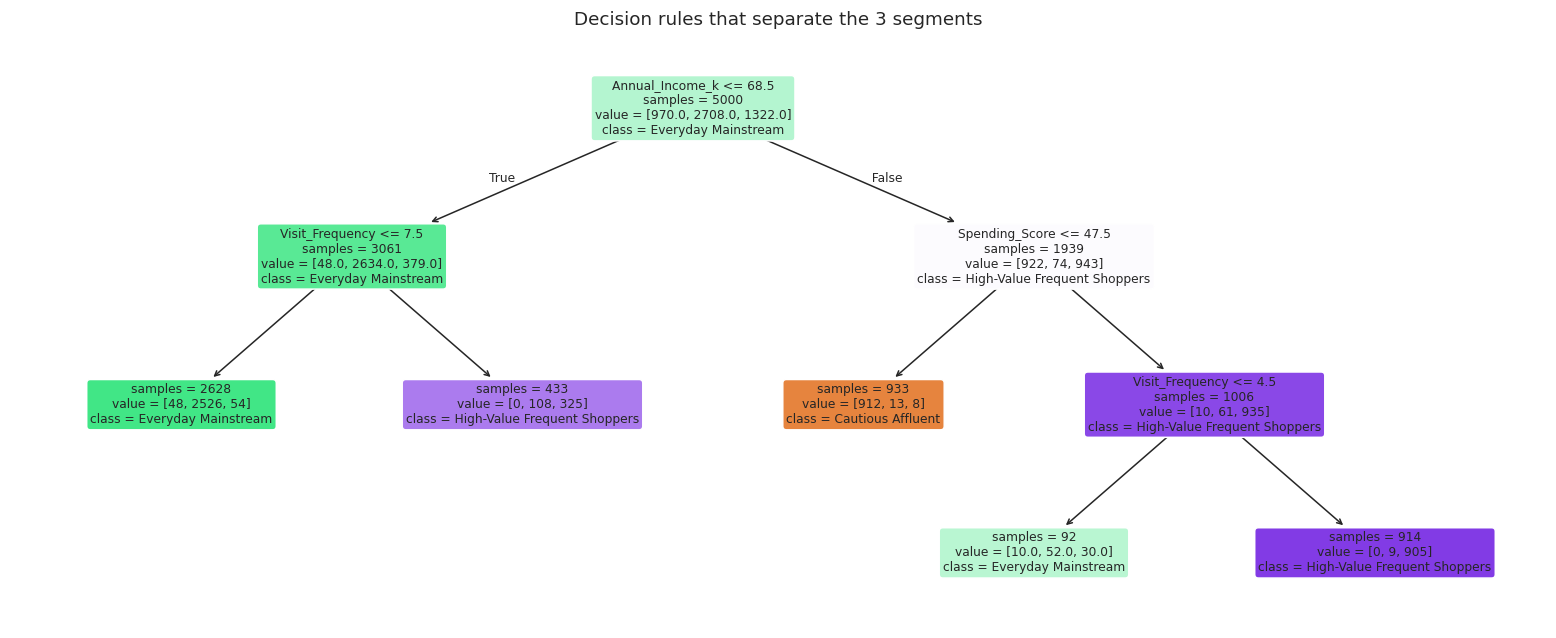

In [25]:
# Simple "segregation rules": a shallow decision tree that re-creates the segments from the 3 raw features
tree = DecisionTreeClassifier(max_depth=3, ccp_alpha=0.01, random_state=SEED)      # pruned so no redundant splits remain
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)                   # shuffled: customer IDs are sorted by income
cv_acc = cross_val_score(tree, df[FEATURES], df["Cluster"], cv=cv).mean()
tree.fit(df[FEATURES], df["Cluster"])
print(f"A small decision tree reproduces the segments with {cv_acc:.1%} cross-validated accuracy.\n")
print(export_text(tree, feature_names=FEATURES))

plt.figure(figsize=(18, 7))
plot_tree(tree, feature_names=FEATURES, class_names=[names[c] for c in range(K)], filled=True, rounded=True, fontsize=8, impurity=False)
plt.title("Decision rules that separate the 3 segments"); plt.show()

**Segregation rules in plain English** (a customer is assigned to the first rule that fits):
1. Income above about 68k **and** spending score up to about 47 -> **Cautious Affluent**.
2. Income above about 68k, spending score above 47 and more than 4 visits per month -> **High-Value Frequent Shoppers** (with 4 visits or fewer -> Everyday Mainstream).
3. Income up to about 68k and more than 7 visits per month -> **High-Value Frequent Shoppers**.
4. Everyone else -> **Everyday Mainstream**.

These rules reproduce the K-Means segments for about 94% of customers, so marketing staff can apply them without running the model.

In [26]:
# Save the customers segregated and sorted by segment (then by income, spending score and visits, highest first)
out = (df[["CustomerID", "Annual_Income_k", "Spending_Score", "Visit_Frequency", "Cluster", "Segment"]]
       .sort_values(["Cluster", "Annual_Income_k", "Spending_Score", "Visit_Frequency"], ascending=[True, False, False, False])
       .reset_index(drop=True))
out.to_csv(f"{DATA_PROC}/bigbazaar_segmented_3clusters.csv", index=False)
summary.to_csv(f"{RESULTS}/segment_summary.csv")
results.to_csv(f"{RESULTS}/model_comparison.csv")

assert out.isna().sum().sum() == 0 and len(out) == out["CustomerID"].nunique() and out["Cluster"].nunique() == K
print("Saved:", sorted(os.listdir(DATA_PROC)), sorted(os.listdir(RESULTS)))
display(out.groupby("Segment").head(2).sort_values("Cluster"))

Saved: ['bigbazaar_raw_3features.csv', 'bigbazaar_segmented_3clusters.csv'] ['model_comparison.csv', 'segment_summary.csv']


,CustomerID,Annual_Income_k,Spending_Score,Visit_Frequency,Cluster,Segment
0,4991,137,26,8.0,0,Cautious Affluent
1,4995,137,24,5.0,0,Cautious Affluent
970,4279,86,96,1.0,1,Everyday Mainstream
971,4186,84,64,4.0,1,Everyday Mainstream
3678,4988,137,86,14.0,2,High-Value Frequent Shoppers
3679,4999,137,86,12.0,2,High-Value Frequent Shoppers


## 10. Conclusion
**Final model:** K-Means with k = 3 on three features (annual income, spending score, visit frequency), after cleaning the raw 5,100-row file down to 5,000 customers. It scored Silhouette 0.341, Davies-Bouldin 0.990 and Calinski-Harabasz 2,869, ahead of Hierarchical (0.291 / 0.962 / 2,112) and Gaussian Mixture (0.294 / 1.210 / 2,065) on silhouette and Calinski-Harabasz. The three segments are highly stable under resampling (bootstrap ARI 0.988).

| Segment | Customers | Profile | Promotion strategy |
|---|---|---|---|
| High-Value Frequent Shoppers | 1,322 (26.4%) | Spending score about 79, about 9 visits/month, income spread widely (avg 75k) | VIP loyalty tier, early access, bundles; avoid heavy discounts |
| Everyday Mainstream | 2,708 (54.2%) | Income about 45k, spending score about 48, about 4 visits/month | Loyalty points, weekly deals, category cross-sell |
| Cautious Affluent | 970 (19.4%) | Income about 85k but spending score about 19 and 3.5 visits/month | Personalised, quality-led offers to raise visits |

**Key insights**
- Income alone does not identify good customers: the highest-earning segment (Cautious Affluent) has the lowest spending score and visits least, while High-Value Frequent Shoppers visit about 2.6 times as often.
- Cautious Affluent is the clearest growth opportunity: high income, low engagement, and a segment that can be reached with targeted rather than blanket offers.
- Three simple rules on income, spending score and visits reproduce the segments for about 94% of customers, so the segmentation can be applied without re-running the model.
- Treating the 72 implausible visit counts as errors matters: leaving them in changes the segments noticeably (ARI about 0.81), while the choice between capping and imputing them does not (ARI above 0.9).

**Limitations**
- **k = 3 is a simplification.** The income vs spending plot shows about five natural blocks, and silhouette is slightly higher at k = 5 (0.370). With three segments, Everyday Mainstream (54% of customers) is broad and mixes several kinds of lower-income shopper. If finer targeting is needed, k = 5 is the natural next step.
- **Moderate separation.** Silhouette of 0.34 means neighbouring segments overlap; 2.6% of customers sit on a segment boundary.
- **Synthetic data.** The 5,000 rows were generated from 200 real customers with added noise, and `Visit_Frequency` was simulated mainly from spending score. The results demonstrate the method and are not findings about real Big Bazaar customers. The bootstrap stability is also likely to be optimistic for the same reason.
- **Imputed visits.** The 272 imputed `Visit_Frequency` values (200 originally missing plus 72 errors) are estimates, so the segment of those customers rests mostly on income and spending score.
- **Static snapshot.** Customers move between segments, so the segmentation should be refreshed periodically.